#### Outcome Model

##### Importing Libraries and Loading Data

In [22]:
# Libraries, and every application with its category (from the form or the classifier)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import make_column_transformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

from planscope.evaluate import evaluate_risk
from planscope.outcome_data import CATEGORIES_PATH, CLEAN_PATH, OUT_PATH, strip_post_submission
from planscope.outcome_model import calibrated_risk, fit

In [2]:
apps = pd.read_parquet(CLEAN_PATH).drop(columns='category')

In [3]:
apps.head()

,id,lpa_name,lpa_app_no,valid_date,decision_date,outcome,decision_process,application_type,description,units_proposed,units_existing,storeys,site_area_ha,lon,lat,uprn,url_planning_app
0,Hounslow-00249_R_O_44_PA1(4-6),Hounslow,00249/R/O/44/PA1(4-6),2022-03-29,2022-07-22,APPROVED,NaN,All Other,Details of Condition 4 (Waste and Recycle) Con...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Hounslow-01122_22_P1_,Hounslow,01122/22/P1,2019-10-03,2019-10-18,OTHER,NaN,All Other,SIDE EXTENSION & RE STUDIO,NaN,NaN,NaN,NaN,-0.303379,51.488912,NaN,NaN
2,Islington-P2025_0550_TRE,Islington,P2025/0550/TRE,2025-02-26,NaT,NaN,NaN,All Other,"Work to be carried out at St Johns Square, Cle...",NaN,NaN,NaN,NaN,-0.103124,51.523063,5300085709,NaN
3,Islington-P2025_0132_LBC,Islington,P2025/0132/LBC,2025-01-27,NaT,NaN,NaN,All Other,Internal adaptation of a space at lower ground...,NaN,NaN,NaN,NaN,-0.105958,51.522498,10093625150,NaN
4,Islington-P2025_0161_LBC,Islington,P2025/0161/LBC,2025-01-17,NaT,APPROVED,NaN,All Other,Proposal to remove and infill non original sin...,NaN,NaN,NaN,NaN,-0.106242,51.538239,5300035278,NaN


In [4]:
apps = apps.merge(pd.read_parquet(CATEGORIES_PATH, columns=['id', 'category']), on='id')

In [5]:
apps.head()

,id,lpa_name,lpa_app_no,valid_date,decision_date,outcome,decision_process,application_type,description,units_proposed,units_existing,storeys,site_area_ha,lon,lat,uprn,url_planning_app,category
0,Hounslow-00249_R_O_44_PA1(4-6),Hounslow,00249/R/O/44/PA1(4-6),2022-03-29,2022-07-22,APPROVED,NaN,All Other,Details of Condition 4 (Waste and Recycle) Con...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conditions
1,Hounslow-01122_22_P1_,Hounslow,01122/22/P1,2019-10-03,2019-10-18,OTHER,NaN,All Other,SIDE EXTENSION & RE STUDIO,NaN,NaN,NaN,NaN,-0.303379,51.488912,NaN,NaN,householder
2,Islington-P2025_0550_TRE,Islington,P2025/0550/TRE,2025-02-26,NaT,NaN,NaN,All Other,"Work to be carried out at St Johns Square, Cle...",NaN,NaN,NaN,NaN,-0.103124,51.523063,5300085709,NaN,trees
3,Islington-P2025_0132_LBC,Islington,P2025/0132/LBC,2025-01-27,NaT,NaN,NaN,All Other,Internal adaptation of a space at lower ground...,NaN,NaN,NaN,NaN,-0.105958,51.522498,10093625150,NaN,listed_building
4,Islington-P2025_0161_LBC,Islington,P2025/0161/LBC,2025-01-17,NaT,APPROVED,NaN,All Other,Proposal to remove and infill non original sin...,NaN,NaN,NaN,NaN,-0.106242,51.538239,5300035278,NaN,listed_building


In [6]:
decided = apps[apps['outcome'].isin(['APPROVED', 'REFUSED'])]

In [7]:
decided.head()

,id,lpa_name,lpa_app_no,valid_date,decision_date,outcome,decision_process,application_type,description,units_proposed,units_existing,storeys,site_area_ha,lon,lat,uprn,url_planning_app,category
0,Hounslow-00249_R_O_44_PA1(4-6),Hounslow,00249/R/O/44/PA1(4-6),2022-03-29,2022-07-22,APPROVED,NaN,All Other,Details of Condition 4 (Waste and Recycle) Con...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conditions
4,Islington-P2025_0161_LBC,Islington,P2025/0161/LBC,2025-01-17,NaT,APPROVED,NaN,All Other,Proposal to remove and infill non original sin...,NaN,NaN,NaN,NaN,-0.106242,51.538239,5300035278,NaN,listed_building
6,Hillingdon-18974_APP_2021_4641,Hillingdon,18974/APP/2021/4641,2021-12-29,2022-02-16,APPROVED,Delegated,All Other,Conversion of roofspace to habitable use to in...,0.0,0.0,NaN,0.039,-0.438001,51.544655,NaN,http://planning.hillingdon.gov.uk/OcellaWeb/pl...,lawful_development
7,Camden-2022_5042_P,Camden,2022/5042/P,2022-11-17,2023-12-11,REFUSED,Delegated,Householder,Erection of a roof extension for the use of th...,NaN,NaN,NaN,0.027,-0.203063,51.553577,5027372,https://planningrecords.camden.gov.uk/Northgat...,householder
8,Westminster-19_09787_FULL,Westminster,19/09787/FULL,2019-12-16,2020-02-06,REFUSED,Delegated,All Other,"Installation of full openable shopfront, insta...",NaN,NaN,NaN,0.059,-0.132071,51.513510,010033548067,NaN,full_planning


In [8]:
apps.shape

(899237, 18)

In [9]:
decided.shape

(721849, 18)

##### Audit

In [10]:
# Share of applications with a decision, by quarter submitted, recent ones are not decided yet

apps['outcome'].isin(['APPROVED', 'REFUSED']).groupby(apps['valid_date'].dt.to_period('Q')).mean().tail(10).round(3)

valid_date
2024Q3    0.827
2024Q4    0.823
2025Q1    0.839
2025Q2    0.815
2025Q3    0.824
2025Q4    0.815
2026Q1    0.805
2026Q2    0.778
2026Q3    0.593
2026Q4    0.080
Freq: Q-DEC, Name: outcome, dtype: float64

In [11]:
# Refusal rate by year submitted. It drifts, so the test set must come after the training set

decided['outcome'].eq('REFUSED').groupby(decided['valid_date'].dt.year).mean().round(3)

valid_date
2019    0.185
2020    0.205
2021    0.198
2022    0.188
2023    0.191
2024    0.175
2025    0.157
2026    0.149
Name: outcome, dtype: float64

In [12]:
# Barking & Dagenham against the rest of London, by type: share decided, and refusal rate when decided

area = apps['lpa_name'].eq('Barking & Dagenham').map({True: 'Barking & Dagenham', False: 'rest of London'})
decided_share = pd.crosstab(apps['category'], area, values=apps['outcome'].isin(['APPROVED', 'REFUSED']), aggfunc='mean')
refusal_rate = pd.crosstab(decided['category'], area.loc[decided.index], values=decided['outcome'].eq('REFUSED'), aggfunc='mean')
pd.concat({'decided share': decided_share, 'refusal rate': refusal_rate}, axis=1).round(3)

decided share                      refusal rate  \
lpa_name           Barking & Dagenham rest of London Barking & Dagenham   
category                                                                  
advert                          0.000          0.881                NaN   
amendment                       0.284          0.859              0.040   
conditions                      0.054          0.813              0.000   
full_planning                   0.908          0.827              0.408   
householder                     0.939          0.914              0.328   
lawful_development              0.022          0.875              0.733   
listed_building                 0.167          0.826              0.000   
other                             NaN          0.829                NaN   
prior_approval                  0.013          0.579              0.458   
trees                           0.000          0.494                NaN   

                                   
lpa_name           rest of London  
category                           
advert                      0.137  
amendment                   0.148  
conditions                  0.086  
full_planning               0.236  
householder                 0.180  
lawful_development          0.182  
listed_building             0.074  
other                       0.088  
prior_approval              0.487  
trees                       0.089

In [13]:
# Text added after submission: appeal links only exist after a refusal; amendment notes appear during negotiation

text = decided['description'].dropna()
note = np.select([text.str.contains('linked cases:', case=False, regex=False), strip_post_submission(text) != text],
                 ['appeal link', 'amendment note'], 'none')
decided.loc[text.index, 'outcome'].eq('REFUSED').groupby(note).agg(['size', 'mean']).round(3)

,size,mean
amendment note,11430,0.152
appeal link,49,1.000
none,710262,0.184


##### Baselines

In [14]:
# The modelling table from outcome_data.py, split by date, first baseline: everyone gets the training refusal rate

df = pd.read_parquet(OUT_PATH)
train, val, test = [df[df['split'] == name] for name in ['train', 'val', 'test']]
results = {'constant': evaluate_risk(test['refused'], np.full(len(test), train['refused'].mean()))}

In [15]:
# Baseline: each authority's refusal rate for the type, shrunk toward London's rate for that type when cases are few

M = 20  # pseudo-cases at London's rate added to every authority and type
type_rate = train.groupby('category')['refused'].mean()
counts = train.groupby(['lpa_name', 'category'])['refused'].agg(['sum', 'size'])
prior = type_rate.reindex(counts.index.get_level_values('category')).to_numpy()
group_rate = ((counts['sum'] + M * prior) / (counts['size'] + M)).rename('rate')
risk = test.join(group_rate, on=['lpa_name', 'category'])['rate'].fillna(test['category'].map(type_rate))
results['authority x type'] = evaluate_risk(test['refused'], risk.fillna(train['refused'].mean()))

In [16]:
# Text only: TF-IDF words and word pairs + logistic regression

text_model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True), LogisticRegression(C=0.5, max_iter=1000))
text_model.fit(train['text'], train['refused'])
results['text only'] = evaluate_risk(test['refused'], text_model.predict_proba(test['text'])[:, 1])

##### Text + Authority + Type + Form

In [17]:
# One model: text features plus one-hot authority, type, authority x type and binned form numbers

GROUPS = ['lpa_name', 'category', 'lpa_category', 'units_proposed', 'storeys', 'site_area_ha']


def outcome_model(C, groups=GROUPS):
    features = make_column_transformer(
        (TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True), 'text'),
        (OneHotEncoder(handle_unknown='ignore', min_frequency=20), groups),
    )
    return make_pipeline(features, LogisticRegression(C=C, max_iter=2000))


# Choose C by validation PR-AUC
best_score, model = 0, None
for C in [0.25, 0.5, 1]:
    candidate = outcome_model(C).fit(train, train['refused'])
    score = average_precision_score(val['refused'], candidate.predict_proba(val)[:, 1])
    print(f'C={C}: validation PR-AUC {score:.4f}')
    if score > best_score:
        best_score, model = score, candidate

C=0.25: validation PR-AUC 0.4377
C=0.5: validation PR-AUC 0.4400
C=1: validation PR-AUC 0.4400


In [18]:
# Does the application form help? The same model without the three form numbers

no_form = outcome_model(model[-1].C, GROUPS[:3]).fit(train, train['refused'])
results['text + groups, no form'] = evaluate_risk(test['refused'], no_form.predict_proba(test)[:, 1])

In [19]:
# Every model on the test year, with 95% confidence intervals

results['text + groups'] = evaluate_risk(test['refused'], model.predict_proba(test)[:, 1])
pd.concat(results)

score  ci_low  ci_high
constant               roc_auc  0.5000  0.5000   0.5000
                       pr_auc   0.1582  0.1559   0.1604
                       brier    0.1344  0.1330   0.1358
authority x type       roc_auc  0.6878  0.6832   0.6927
                       pr_auc   0.3050  0.2981   0.3123
                       brier    0.1266  0.1251   0.1280
text only              roc_auc  0.7517  0.7473   0.7562
                       pr_auc   0.3866  0.3785   0.3946
                       brier    0.1171  0.1156   0.1184
text + groups, no form roc_auc  0.7600  0.7559   0.7645
                       pr_auc   0.4043  0.3963   0.4125
                       brier    0.1163  0.1148   0.1177
text + groups          roc_auc  0.7449  0.7405   0.7493
                       pr_auc   0.3917  0.3835   0.4000
                       brier    0.1212  0.1198   0.1226

In [20]:
# Why does the form hurt? Share of applications with any form number, and refusal rate with and without, by split

has_form = df[['units_proposed', 'storeys', 'site_area_ha']].ne('missing').any(axis=1)
df.groupby(['split', has_form.rename('has_form')])['refused'].agg(['size', 'mean']).unstack().round(3)

size           mean       
has_form  False   True   False  True 
split                                
test      38263   48736  0.136  0.175
train     52411  429634  0.180  0.195
val       15286   73122  0.158  0.181

In [21]:
# Decide on validation, PR-AUC on the validation year with and without the form

{name: round(average_precision_score(val['refused'], m.predict_proba(val)[:, 1]), 4) for name, m in [('with form', model), ('no form', no_form)]}

{'with form': 0.44, 'no form': 0.4473}

##### Final Model and Calibration

In [23]:
# The chosen model, fitted on train and calibrated on val (outcome_model.py does the same one year later)

final, a, b = fit(train, val)
raw = final.predict_proba(test)[:, 1]
calibrated = calibrated_risk(final, a, b, test)
print(f'a={a:.3f}, b={b:.3f}')
pd.concat({'raw': evaluate_risk(test['refused'], raw), 'calibrated': evaluate_risk(test['refused'], calibrated)})

a=0.979, b=-0.040


score  ci_low  ci_high
raw        roc_auc  0.7616  0.7575   0.7659
           pr_auc   0.4058  0.3980   0.4142
           brier    0.1157  0.1143   0.1170
calibrated roc_auc  0.7616  0.7575   0.7659
           pr_auc   0.4058  0.3980   0.4142
           brier    0.1155  0.1140   0.1168

In [24]:
# Reliability: 10 equal groups by risk; mean predicted risk against the actual refusal rate in each

deciles = pd.qcut(calibrated, 10, labels=False)
reliability = pd.DataFrame({'raw': raw, 'calibrated': calibrated, 'refused': test['refused'].to_numpy()}).groupby(deciles).mean()
reliability.round(3)

,raw,calibrated,refused
0,0.019,0.019,0.017
1,0.048,0.049,0.044
2,0.071,0.071,0.063
3,0.094,0.094,0.084
4,0.119,0.119,0.106
5,0.150,0.149,0.128
6,0.188,0.187,0.158
7,0.244,0.241,0.218
8,0.338,0.332,0.294
9,0.558,0.548,0.469


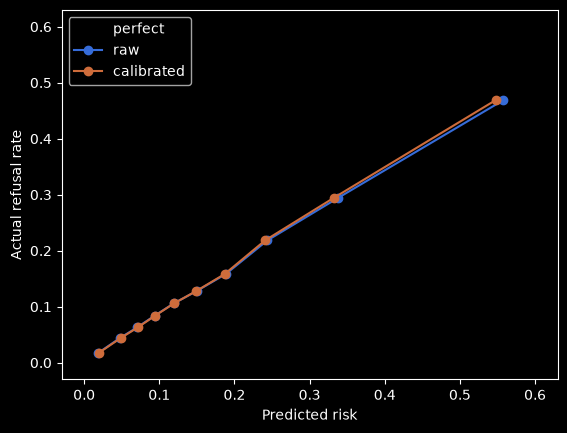

In [25]:
# The same as a picture: points on the dashed line mean a risk of x% really is refused x% of the time

plt.plot([0, 0.6], [0, 0.6], 'k--', label='perfect')
plt.plot(reliability['raw'], reliability['refused'], 'o-', label='raw')
plt.plot(reliability['calibrated'], reliability['refused'], 'o-', label='calibrated')
plt.xlabel('Predicted risk')
plt.ylabel('Actual refusal rate')
plt.legend()
plt.show()

In [26]:
# Lift: refusal rate among the 10% riskiest applications, against all applications

print(f"Top 10%: {reliability['refused'].iloc[-1]:.1%} refused, against {test['refused'].mean():.1%} overall")

Top 10%: 46.9% refused, against 15.8% overall


##### Error Analysis

In [27]:
# Where does it work? Size, refusal rate and ROC-AUC by type

scored = test.assign(risk=calibrated)
scored.groupby('category').apply(lambda g: pd.Series({
    'applications': len(g), 'refusal_rate': g['refused'].mean(),
    'roc_auc': roc_auc_score(g['refused'], g['risk']) if g['refused'].nunique() == 2 else np.nan})).round(3)

,applications,refusal_rate,roc_auc
category,,,
advert,2682.0,0.144,0.747
amendment,2756.0,0.129,0.746
conditions,15427.0,0.082,0.733
full_planning,20775.0,0.220,0.789
householder,24073.0,0.143,0.699
lawful_development,10991.0,0.171,0.660
listed_building,1940.0,0.074,0.700
other,6.0,0.000,NaN
prior_approval,3525.0,0.381,0.716


In [28]:
# The words and word pairs that most raise and most lower the risk

text_features = final[0].named_transformers_['tfidfvectorizer'].get_feature_names_out()
weights = final[-1].coef_[0][:len(text_features)]
order = np.argsort(weights)
pd.DataFrame({'raises risk': text_features[order[-15:][::-1]], 'lowers risk': text_features[order[:15]]})

,raises risk,lowers risk
0,tpo,plant
1,retrospective,description
2,hmo,dead
3,fell,replacement
4,cabinets,end application
5,projecting from,only
6,depth,window application
7,dwelling,prune
8,shisha,points
9,advertisement,temporary


In [29]:
# The most confident mistakes: approvals the model called risky, and refusals it called safe

pd.set_option('display.max_colwidth', 110)
cols = ['lpa_name', 'category', 'risk', 'text']
pd.concat({'approved but high risk': scored[scored['refused'] == 0].nlargest(5, 'risk')[cols],
           'refused but low risk': scored[scored['refused'] == 1].nsmallest(5, 'risk')[cols]})

lpa_name            category      risk  \
approved but high risk 656481    Lewisham      prior_approval  0.970798   
                       452704    Havering  lawful_development  0.963985   
                       450078    Havering  lawful_development  0.943113   
                       520277    Havering  lawful_development  0.934338   
                       653748    Lewisham      prior_approval  0.932099   
refused but low risk   407124  Wandsworth               trees  0.002216   
                       408004  Wandsworth               trees  0.002463   
                       513489  Wandsworth               trees  0.003667   
                       80839   Wandsworth               trees  0.004315   
                       255756  Wandsworth               trees  0.004982   

                                                                                                                                        text  
approved but high risk 656481  Application for Prior Approval under Schedule 2, Part 20, Class AA of the Town and Country Planning (Gener...  
                       452704                                                                                    Use of Outbuilding as Annex  
                       450078  Part single, part double storey rear extension, two storey front extension, rear dormer extension, and alt...  
                       520277                                 Certificate of lawfulness for existing use of residential flat on ground floor  
                       653748  Application for Prior Approval under Schedule 2, Part 1, Class A, Part (g) of the Town and Country Plannin...  
refused but low risk   407124  T1 Red oak: Reduce by approx. 2m back to previous points of reduction. T2 English oak: Reduce by approx. 2...  
                       408004  Tree Preservation Order 133/1990 -T93 & T94 Lime trees: Crown reduce to most recent reduction points, thin...  
                       513489  Tree Preservation (No.100) Order 1971 T15 English Oak: Reduce by approx. 2m back to previous points of red...  
                       80839   TPO 5/1960 T10 Lime - To crown reduce back to previous points removing approximately 5 meters from the bra...  
                       255756  Lime T37 (front garden). Crown reduction to remove all new growth back to previous pruning points - 4 metr...

##### Findings and Decisions
- **Task:** predict the chance an application is refused (1) rather than approved (0), using only what is known when it is submitted. Withdrawn and other outcomes are excluded, so the risk means "if decided, how likely is a refusal".
- **Data:** 899,237 applications, 721,849 approved or refused. Modelling table (with a description, not censored): train 482,045, val 88,408, test 86,999 (15.8% refused).
- **Censoring:** about 82% of applications are decided, steady until 2026Q1 (0.805); then 0.778, 0.593 and 0.080 for the latest quarters, which are not decided yet. The newest 12 months are left out entirely.
- **Drift:** refusal rate 0.185 to 0.205 for 2019–2023, then 0.175 (2024), 0.157 (2025) and 0.149 (2026). The split is therefore by date: train = everything up to 3 years before the cut-off, val = the next 12 months, test = the 12 months ending a year before the newest application. Windows are computed from the data, so they move forward with each re-pull.
- **Leakage removed:** Hackney appends "Linked cases: APP/U5360/..." planning appeal references, which only exist after a refusal (49 applications, 100% refused). Councils also append amendment notes during negotiation (11,430 applications, 15.2% refused vs 18.4%). `strip_post_submission` removes both before any model sees the text.
- **Barking & Dagenham:** its feed reports decisions mostly for householder (0.939 decided) and full planning (0.908); most other types are rarely decided (0.000–0.284 vs 0.494–0.881 elsewhere). Within a type it still refuses more (householder 0.328 vs 0.180), so the model learns authority × type, not authority alone.
- **Results on the test year (95% bootstrap CIs):**

| Model | ROC-AUC | PR-AUC | Brier |
|---|---|---|---|
| Constant | 0.500 | 0.158 | 0.1344 |
| Authority × type rate (shrunk, M = 20) | 0.688 (0.683–0.693) | 0.305 (0.298–0.312) | 0.1266 |
| Text only (TF-IDF + LR) | 0.752 (0.747–0.756) | 0.387 (0.379–0.395) | 0.1171 |
| **Text + authority + type + authority × type** | **0.760 (0.756–0.765)** | **0.404 (0.396–0.413)** | **0.1163** |
| Same + binned form numbers | 0.745 (0.741–0.749) | 0.392 (0.384–0.400) | 0.1212 |

- - **Chosen model:** text + authority + type + authority × type, logistic regression. Validation PR-AUC was 0.4377 / 0.4400 / 0.4400 for C = 0.25 / 0.5 / 1, a tie to four decimals between 0.5 and 1; the final model uses C = 0.5, the simpler of the two. PR-AUC is 2.6× the no-skill line.
- **Form fields dropped:** worse on validation (PR-AUC 0.4400 vs 0.4473) and on test. Their coverage falls over time (89% of train, 83% of val, 56% of test), and what "missing" signals keeps changing (refusal gap 1.5, 2.3, 3.9 points). Live, users would always or never supply them, unlike any training year.
- **LightGBM not used:** a stacked LightGBM (text score + authority + type + location), tested outside this notebook on the July 2026 snapshot, matched ROC-AUC (0.763) with lower PR-AUC (0.412 vs 0.426). The linear model is simpler, explains itself and is easy to serve.
- - **Final model and calibration:** fitted on train, Platt-calibrated on val (a = 0.979, b = −0.040). Test: ROC-AUC 0.762 (0.758–0.766), PR-AUC 0.406 (0.398–0.414), Brier 0.1157 raw and 0.1155 calibrated. The model was already calibrated for its training years; what remains is drift (riskiest tenth predicted 0.548, refused 0.469; lowest tenth 0.019 vs 0.017). The exported model is calibrated on the most recent decided year, which anchors its average risk to that year's refusal rate, and is retrained with every data refresh.
- **Lift:** the riskiest 10% were refused 46.9% of the time, against 15.8% overall (3.0×).
- **By type (ROC-AUC):** full planning 0.789, trees 0.783, advert 0.747, amendment 0.746, conditions 0.733, prior approval 0.716, listed building 0.700, householder 0.699, lawful development 0.660. Lawful development turns on facts (dates, existing use) that descriptions rarely state.
- **Words:** raising risk: tpo, retrospective, hmo, fell, cabinets, shisha, hub, advertisement, eaves height; lowering it: plant, dead, replacement, prune, temporary, school, details. "description" among the lowering words is residual amendment notes in formats the strip rule misses, such as "(description amended)" and "[AND DESCRIPTION]" (about 2,000 descriptions, refused 7.6% vs 18.8%, July snapshot). Widening the rule left test metrics unchanged to three decimals, so this is a documented limitation rather than a fix.
- **Confident mistakes:** approved Lewisham prior approvals (upward extensions) and Havering lawful development certificates scored 93–97%; refused Wandsworth crown reductions "back to previous points" scored 0.2–0.5%. Such tree works are refused only about 2–3% of the time (July snapshot), so occasional refusals at very low risk are expected, not a data error.
- **Serving:** exported as plain numbers (models/outcome.json) and scored with numpy in `planscope.risk`, keeping scikit-learn out of Lambda. Tests check the served risk matches scikit-learn to 1e-5 and that serving text preparation matches training.
- **Next (13c):** /predict endpoint, deployment, and the risk box on the page.